<a href="https://colab.research.google.com/github/TanusnSN/4NI25CS208_DAV_LAB/blob/main/4NI25CS208_EXP_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale'].copy()
df['Area'] = df['Area Size']
df.loc[df['Area Type'] == 'Kanal', 'Area'] = df['Area Size'] * 20
df = df[(df['Area'] > 0) & (df['price'] > 0)]
df = df[(df['Area'] < df['Area'].quantile(0.99)) & (df['price'] < df['price'].quantile(0.99))]
X = df[['Area', 'price']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


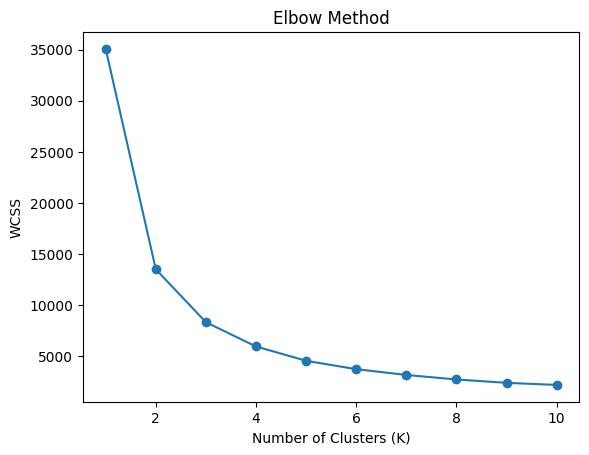

In [ ]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method'); plt.show()

In [7]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area', 'price']].mean())

Cluster
0    9937
1    2181
2    4726
3     688
Name: count, dtype: int64
              Area         price
Cluster                         
0         4.537144  8.032230e+06
1        19.612105  4.800367e+07
2         9.789568  2.257168e+07
3        29.238227  1.178903e+08


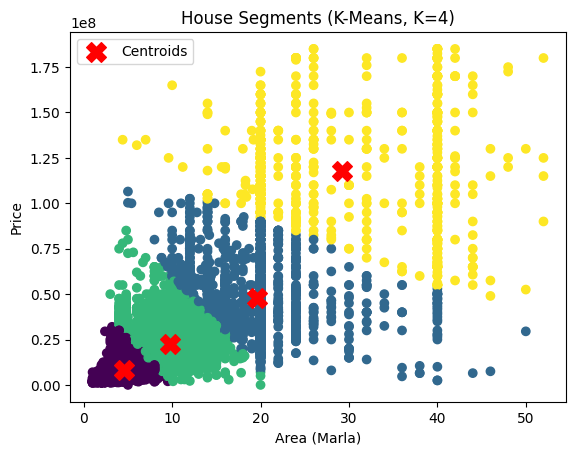

In [10]:
plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Area (Marla)')
plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)')
plt.legend()
plt.show()